# Thực hành 2 — Các biến thể CNN

**Lê Sơn Trường — Buổi 4**. Theo `De_bai/baitap.txt` và các file mẫu.

Chọn **Select Kernel → DeepL (PyTorch)**. Môi trường có sẵn: `Buoi1/Buoi1_PyTorch/.venv/Scripts/python.exe`.

Notebook đã có output. **Run All huấn luyện lại thực sự** với 5 epoch mỗi cấu hình và cập nhật kết quả trong `results/`. Các hàm dùng trực tiếp từ `.py`; cell hiển thị mã lấy đúng nguồn hàm hiện tại, tránh hai bản code khác nhau.

## Quy trình chạy — Thực hành 2: khảo sát các biến thể CNN

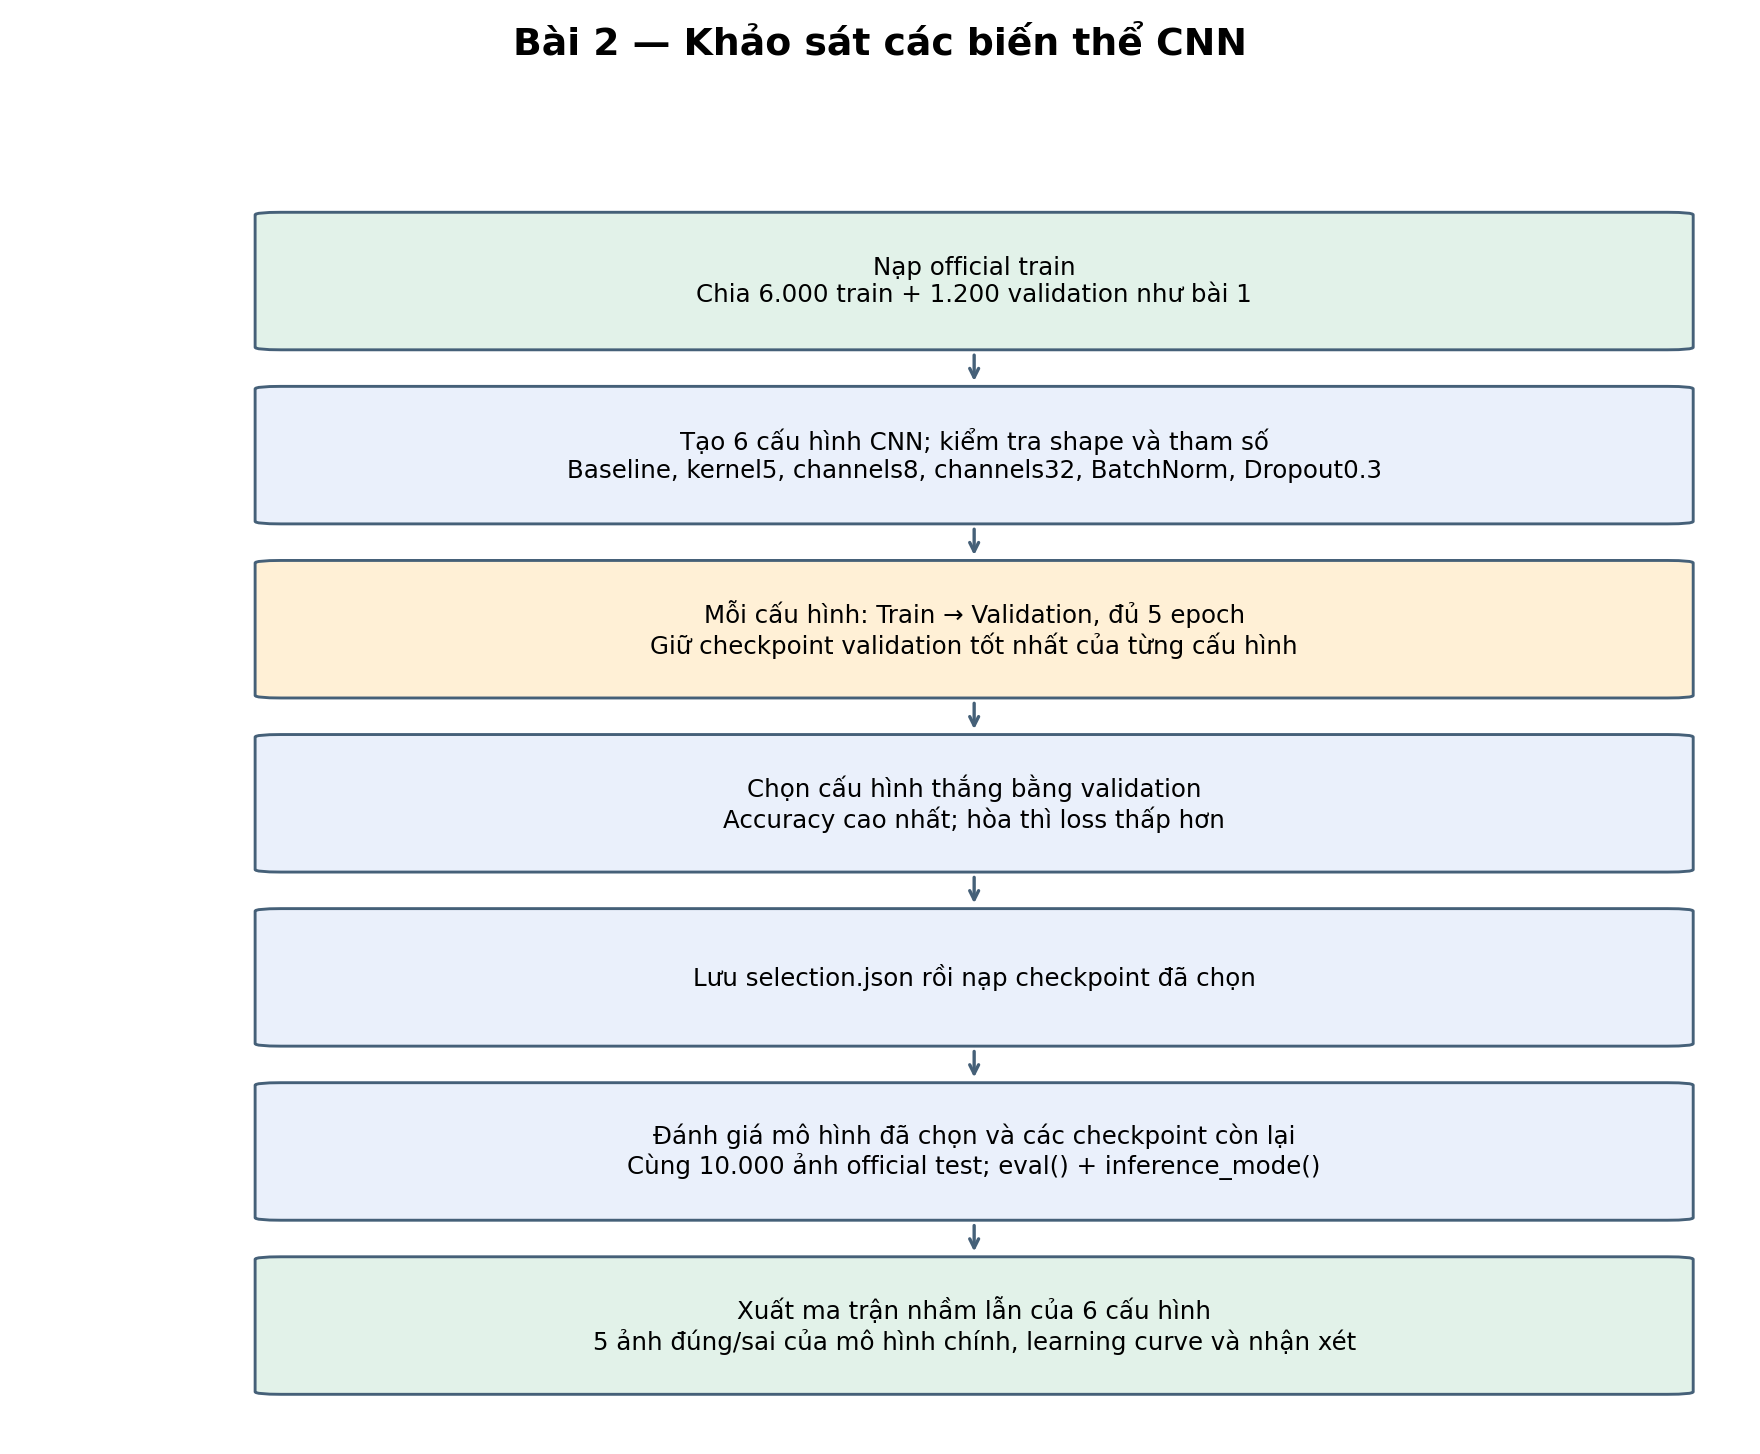

<details>
<summary>Mã Mermaid để chỉnh sửa sơ đồ</summary>

```mermaid
flowchart TD
    N0["Nạp official train<br/>Chia 6.000 train + 1.200 validation như bài 1"]
    N1["Tạo 6 cấu hình CNN; kiểm tra shape và tham số<br/>Baseline, kernel5, channels8, channels32, BatchNorm, Dropout0.3"]
    N0 --> N1
    N2["Mỗi cấu hình: Train → Validation, đủ 5 epoch<br/>Giữ checkpoint validation tốt nhất của từng cấu hình"]
    N1 --> N2
    N3["Chọn cấu hình thắng bằng validation<br/>Accuracy cao nhất; hòa thì loss thấp hơn"]
    N2 --> N3
    N4["Lưu selection.json rồi nạp checkpoint đã chọn"]
    N3 --> N4
    N5["Đánh giá mô hình đã chọn và các checkpoint còn lại<br/>Cùng 10.000 ảnh official test; eval() + inference_mode()"]
    N4 --> N5
    N6["Xuất ma trận nhầm lẫn của 6 cấu hình<br/>5 ảnh đúng/sai của mô hình chính, learning curve và nhận xét"]
    N5 --> N6
```

</details>


**Luồng đọc nhanh:**

```text
Nạp official train → Chia 6000 train / 1200 validation
→ Với mỗi cấu hình: tạo CNN/optimizer rồi chạy
  5 × [Train 1 epoch → Validation → Cập nhật checkpoint tốt nhất]
→ Chọn cấu hình thắng và lưu selection.json → Nạp official test
→ Đánh giá 10000 ảnh test → Ma trận mô hình chính và cả 6 cấu hình
→ 5 ảnh đúng + 5 ảnh sai của mô hình chính
→ Xuất bảng so sánh, learning curve và báo cáo
```

| Bước | Công việc | Hàm thực hiện | Kết quả / ý nghĩa |
|---:|---|---|---|
| 1 | Khởi tạo và chia dữ liệu | `main()` → `set_seed()` → `make_data()` | Cùng split6000/1200 từ official train như bài 1; xác định device. Chưa nạp test ở bước này. |
| 2 | Khai báo và xem kiến trúc | `experiments()` → `export_architectures()` → `describe_cnn()` | Baseline; kernel5; channels8; channels32; BatchNorm; Dropout0.3. Mỗi biến thể chỉ đổi một thuộc tính; lưu cấu hình, shape từng lớp với batch 1/64 và tham số theo block/phân loại. Kiểm tra shape bằng input giả ở eval, trước khi tính thời gian huấn luyện. |
| 3 | Học từng cấu hình | Vòng lặp trong `main()` → `fit()` | Reset seed và batch order, dựng CNN và Adam LR0.001; chạy đủ 5 epoch. Mỗi epoch học trên train rồi đo val loss/accuracy, ghi thời gian. |
| 4 | Giữ checkpoint từng cấu hình | Trong `fit()` | Chọn epoch có val accuracy lớn nhất; hòa thì dùng val loss nhỏ hơn, hòa cả hai giữ epoch gặp trước. Lưu `<tên>_best.pt`. |
| 5 | Chọn cấu hình thắng | Sau vòng lặp cấu hình trong `main()` | So sánh các checkpoint tốt nhất bằng cùng quy tắc validation. Lưu quyết định vào `selection.json` trước khi gọi đánh giá test. |
| 6 | Đánh giá cuối và đối chiếu lỗi | Nạp checkpoint → `final_test()` → `evaluate_all_configurations()` | Nạp đủ 10.000 ảnh official test; eval() và inference_mode(), không cập nhật trọng số. Xuất test loss/accuracy và ma trận của mô hình đã chọn; bổ sung ma trận cả 6 checkpoint tốt nhất theo validation để đối chiếu lỗi. |
| 7 | Xuất kết quả | `final_test()` và phần cuối `main()` | Lưu đủ dự đoán test, ma trận CSV/PNG, 5 ảnh đúng và 5 ảnh sai đầu tiên có nhãn thật/dự đoán; hoàn thiện bảng cấu hình, learning curve, kết quả từng epoch và nhận xét. |

**Chọn epoch và cấu hình hoàn toàn bằng validation.** Các ma trận test của 6 cấu hình là phân tích bổ sung; giữ nguyên mô hình chính đã chọn trong `selection.json`.

**File kết quả trong `results/thuc_hanh_2/`:** `split.json`, `configurations.json`, `architectures.json`, `shapes.txt`, `history.csv`, `summary.csv`, `metadata.json`, các checkpoint `*_best.pt`, `selection.json`, `test_metrics.json`, `test_predictions.csv`, `confusion_matrix.csv/png`, `example_indices.csv`, `correct_examples.png`, `incorrect_examples.png`, `learning_curves.png`, `report.md`, `test_all_configs/summary.csv`, `test_all_configs/confusion_matrices.png` và thư mục ma trận/dự đoán riêng cho mỗi cấu hình.


In [1]:
from pathlib import Path
import importlib
import inspect
import re
import sys

cwd = Path.cwd().resolve()
candidates = [cwd, cwd / "Buoi4", *[p / "Buoi4" for p in cwd.parents]]
BASE = next((p for p in candidates if (p / "De_bai" / "baitap.txt").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Mở notebook từ repository DeepL hoặc thư mục Buoi4.")
sys.path.insert(0, str(BASE))
try:
    import torch
except ModuleNotFoundError as error:
    if error.name != "torch":
        raise
    raise ModuleNotFoundError(
        "Chọn Select Kernel -> DeepL (PyTorch), rồi Restart Kernel và Run All. "
        f"Python hiện tại chưa có torch: {sys.executable}"
    ) from error

# Nạp đúng mã của Buổi 4, kể cả khi kernel đã dùng common.py của buổi khác.
importlib.invalidate_caches()
for name in ["reporting", "common", "bai03_class_cnn_fashionmnist", "bai03_homework_cnn_variants", "build_notebooks"]:
    sys.modules.pop(name, None)
import common
from IPython.display import Code, Image, Markdown, display
common.set_seed()
print("Người làm: Lê Sơn Trường")
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| device:", common.DEVICE)
print("Train/validation: 6000/1200 từ official train; Adam; LR=0.001; batch64; 5 epoch.")

import bai03_homework_cnn_variants as exercise

Người làm: Lê Sơn Trường
Python: C:\Users\LeSonTruong\Documents\GitHub\DeepL\Buoi1\Buoi1_PyTorch\.venv\Scripts\python.exe
PyTorch: 2.14.1+cpu | device: cpu
Train/validation: 6000/1200 từ official train; Adam; LR=0.001; batch64; 5 epoch.


## 1. Đầu vào, đầu ra và cách chia dữ liệu

Fashion-MNIST: ảnh xám `(N,1,28,28)`, nhãn long 0–9. Chuyển ảnh thành float32 /255, không augmentation. Train 6.000 và validation 1.200 ảnh không giao nhau, lấy từ cùng hoán vị official train với seed42. Đầu ra là 10 logits; `argmax` cho lớp dự đoán.

Chọn checkpoint và cấu hình bằng validation accuracy; hòa thì xét loss thấp hơn. Chỉ sau đó mới đánh giá trên toàn bộ 10.000 ảnh official test.

In [2]:
display(Code(inspect.getsource(common.make_data), language="python"))

def make_data(output):
    images, labels = read_official(train=True)
    ids = torch.randperm(len(labels), generator=torch.Generator().manual_seed(SEED))
    train_ids, val_ids = ids[:TRAIN_SIZE], ids[TRAIN_SIZE:TRAIN_SIZE + VAL_SIZE]
    assert not set(train_ids.tolist()) & set(val_ids.tolist())
    save_json(output / "split.json", {"seed": SEED, "source": "official train",
                                     "train_indices": train_ids.tolist(),
                                     "validation_indices": val_ids.tolist()})
    return tuple(TensorDataset(images[i].float().div_(255), labels[i])
                 for i in (train_ids, val_ids))

## 2. Baseline và các cấu hình khảo sát

Baseline: channels16/32, kernel3, không BatchNorm/Dropout. Các biến thể: kernel5, channels8/16, channels32/64, BatchNorm, Dropout0.3. Tổng cộng 6 cấu hình, bao phủ kernel3/5 và channel block1 8/16/32; block2 có số kênh gấp đôi block1. Mỗi biến thể chỉ thay một thuộc tính so với baseline.

### CNN hai block: dữ liệu đi qua mạng thế nào?

CNN **hai block** nghĩa là lặp hai lần cụm
**Conv2d → ReLU → MaxPool2d(2)**. Sau hai block mới đến phần phân loại.
Trong `common.py`, xem các chú thích `BLOCK 1`, `BLOCK 2`, `PHÂN LOẠI`
ở hàm `CNN2Blocks.forward()`.

Ví dụ dưới đây dùng **baseline**: kernel3, channels16/32, không BatchNorm/Dropout.
`N` là số ảnh trong batch (thường là 64), không phải số kênh.
Shape luôn có thứ tự **(số ảnh, số kênh, chiều cao, chiều rộng)**.

```text
Ảnh xám (N,1,28,28)
  │
  ├─ BLOCK 1
  │   Conv2d(1,16,3,padding=1) → (N,16,28,28)
  │   ReLU                    → (N,16,28,28)
  │   MaxPool2d(2)            → (N,16,14,14)
  │
  ├─ BLOCK 2
  │   Conv2d(16,32,3,padding=1)→ (N,32,14,14)
  │   ReLU                    → (N,32,14,14)
  │   MaxPool2d(2)            → (N,32,7,7)
  │
  └─ PHÂN LOẠI
      Flatten → (N,1568) → Linear → (N,128) → ReLU
      → Linear → (N,10) logits → argmax → nhãn dự đoán
```

**Bên trong từng phép tính:**

| Phép tính | Thực hiện thế nào? | Ý nghĩa |
|---|---|---|
| Conv2d | Trượt bộ lọc trên ảnh/đặc trưng. Tại mỗi vị trí, nhân từng giá trị với trọng số tương ứng, cộng lại trên cả vùng và các kênh đầu vào, rồi cộng bias. | Học đặc trưng cục bộ; dùng cùng trọng số ở các vị trí. |
| ReLU | Tính `max(0,x)`: số âm thành 0, số dương giữ nguyên. Không đổi shape. | Tạo tính phi tuyến, giúp mạng học quan hệ phức tạp. |
| MaxPool2d(2) | Mỗi kênh chia thành vùng 2×2, lấy giá trị lớn nhất; mặc định stride=2. | Giảm chiều cao/rộng còn một nửa, giữ số kênh. |

**Cụ thể với hai block:** Conv1 có 16 bộ lọc, mỗi bộ kích thước
`1×3×3`, tạo 16 bản đồ đặc trưng. Conv2 có 32 bộ lọc, mỗi bộ
`16×3×3`: mỗi giá trị đầu ra tổng hợp thông tin từ **cả 16 kênh**
của block 1, tạo 32 bản đồ đặc trưng mới. Các bộ lọc do mạng học
trong lúc huấn luyện, không phải bộ dò cạnh được đặt sẵn.

`padding=1` thêm viền 0 để convolution kernel3, stride1 giữ nguyên kích thước.
Công thức với dilation=1 là `H_out = floor((H + 2p - k)/s) + 1`;
ở conv1: `(28 + 2×1 - 3)/1 + 1 = 28`. Pooling mới giảm
`28→14` rồi `14→7`. Số ảnh trong batch luôn được giữ nguyên.

**Ví dụ nhỏ cho ReLU và MaxPool** (số minh họa, không phải kết quả huấn luyện):

```text
Một vùng đặc trưng    Sau ReLU        Sau MaxPool2d(2)
[-2,  3]             [0, 3]
[ 1, -4]       →     [1, 0]      →    3
```

**Sau hai block:** `32×7×7 = 1568` giá trị được trải phẳng cho mỗi ảnh.
`Linear(1568,128) → ReLU → Linear(128,10)` tạo 10 điểm số **logits**.
`argmax` chọn lớp có điểm cao nhất. Khi học, đưa logits trực tiếp vào
`CrossEntropyLoss`; không cần thêm Softmax trước loss.

**Các biến thể trong bài 2:**

- Kernel5 dùng padding2 nên vẫn giữ nguyên H,W sau convolution.
- Channels8 nghĩa là hai block có 8/16 kênh; channels32 nghĩa là 32/64 kênh.
  H,W vẫn đi theo `28→14→7`; số chiều sau Flatten thay đổi theo số kênh.
- BatchNorm: mỗi block thành `Conv2d → BatchNorm2d → ReLU → MaxPool2d(2)`.
  Ở baseline, `bn1/bn2` là `Identity`, cho dữ liệu đi qua nguyên vẹn.
- Dropout0.3 nằm **sau ReLU của Linear128**, ngoài hai block convolution.
  Nó ngẫu nhiên đặt một phần giá trị về 0 khi train; tắt khi eval.

**Liên hệ với quá trình học:** luồng trên là **forward**. Tiếp theo,
`loss → backward → optimizer.step()` tính lỗi, truyền gradient ngược
và cập nhật trọng số. Conv2d và Linear có tham số học được; ReLU,
MaxPool và Flatten không có trọng số học được. Với biến thể BatchNorm,
các tham số scale/bias của BatchNorm cũng được học.


In [3]:
display(Code(inspect.getsource(common.CNN2Blocks), language="python"))
display(Code(inspect.getsource(exercise.experiments), language="python"))
display(exercise.experiments())
from reporting import variant_architecture_markdown
architecture_output = BASE / "results" / "thuc_hanh_2"
architecture_output.mkdir(parents=True, exist_ok=True)
architectures = exercise.export_architectures(exercise.experiments(), architecture_output, verbose=True)
display(Markdown(variant_architecture_markdown(architectures)))

class CNN2Blocks(nn.Module):
    """Hai block trích đặc trưng rồi phân loại; N là số ảnh trong batch.

    Baseline: channels=16, kernel_size=3, không BatchNorm/Dropout.
    Mỗi block: Conv2d -> ReLU -> MaxPool2d(2).
    Biến thể BatchNorm chèn BN giữa Conv2d và ReLU.
    """

    def __init__(self, channels=16, kernel_size=3, batchnorm=False, dropout=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(1, channels, kernel_size, padding=kernel_size // 2)
        self.bn1 = nn.BatchNorm2d(channels) if batchnorm else nn.Identity()
        self.conv2 = nn.Conv2d(channels, 2 * channels, kernel_size, padding=kernel_size // 2)
        self.bn2 = nn.BatchNorm2d(2 * channels) if batchnorm else nn.Identity()
        self.relu, self.pool = nn.ReLU(), nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(2 * channels * 7 * 7, 128)
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # BLOCK 1: (N,1,28,28) -> (N,C,14,14), baseline C=16.
        x = self.conv1(x)  # Học C bộ lọc: (N,C,28,28); padding giữ H,W.
        x = self.bn1(x)    # Identity ở baseline; BatchNorm ở biến thể BN.
        x = self.relu(x)   # max(0,x): bỏ giá trị âm, giữ nguyên shape.
        x = self.pool(x)   # Lấy max mỗi ô 2x2: 28x28 -> 14x14.

        # BLOCK 2: (N,C,14,14) -> (N,2C,7,7), baseline 2C=32.
        x = self.conv2(x)  # Mỗi bộ lọc kết hợp C kênh: (N,2C,14,14).
        x = self.bn2(x)
        x = self.relu(x)
        x = self.pool(x)   # 14x14 -> 7x7; không thay số kênh.

        # PHÂN LOẠI: (N,2C,7,7) -> (N,2C*7*7) -> (N,128) -> (N,10).
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.drop(x)   # p=0 ở baseline; p=0.3 ở biến thể Dropout.
        return self.fc2(x)  # 10 logits; CrossEntropyLoss nhận trực tiếp.

def experiments():
    baseline = dict(channels=16, kernel_size=3, batchnorm=False, dropout=0.0)
    return [dict(name="baseline", **baseline),
            dict(name="kernel5", **{**baseline, "kernel_size": 5}),
            dict(name="channels8", **{**baseline, "channels": 8}),
            dict(name="channels32", **{**baseline, "channels": 32}),
            dict(name="batchnorm", **{**baseline, "batchnorm": True}),
            dict(name="dropout03", **{**baseline, "dropout": 0.3})]

[{'name': 'baseline',
  'channels': 16,
  'kernel_size': 3,
  'batchnorm': False,
  'dropout': 0.0},
 {'name': 'kernel5',
  'channels': 16,
  'kernel_size': 5,
  'batchnorm': False,
  'dropout': 0.0},
 {'name': 'channels8',
  'channels': 8,
  'kernel_size': 3,
  'batchnorm': False,
  'dropout': 0.0},
 {'name': 'channels32',
  'channels': 32,
  'kernel_size': 3,
  'batchnorm': False,
  'dropout': 0.0},
 {'name': 'batchnorm',
  'channels': 16,
  'kernel_size': 3,
  'batchnorm': True,
  'dropout': 0.0},
 {'name': 'dropout03',
  'channels': 16,
  'kernel_size': 3,
  'batchnorm': False,
  'dropout': 0.3}]

Shape probe: zero input, CPU, eval mode; not training/test predictions.

=== baseline | parameters=206,922 ===
input: (1, 1, 28, 28)
conv1: (1, 16, 28, 28) | Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
bn1: (1, 16, 28, 28) | Identity()
relu1: (1, 16, 28, 28) | ReLU()
pool1: (1, 16, 14, 14) | MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
conv2: (1, 32, 14, 14) | Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
bn2: (1, 32, 14, 14) | Identity()
relu2: (1, 32, 14, 14) | ReLU()
pool2: (1, 32, 7, 7) | MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
flatten: (1, 1568) | Flatten(start_dim=1, end_dim=-1)
fc1: (1, 128) | Linear(in_features=1568, out_features=128, bias=True)
relu3: (1, 128) | ReLU()
drop: (1, 128) | Dropout(p=0.0, inplace=False)
fc2: (1, 10) | Linear(in_features=128, out_features=10, bias=True)
input: (64, 1, 28, 28)
conv1: (64, 16, 28, 28) | Conv2d(1, 16, kernel_size=(3, 3), stride=(1,

### Kiến trúc và shape của đủ 6 cấu hình

Shape có thứ tự `(N,C,H,W)`; N là số ảnh trong batch. Các shape dưới đây được ghi bằng hook trên `forward()` thật, với input giả bằng 0, chế độ eval trên CPU; đây là kiểm tra kiến trúc.

| Cấu hình | Sau Conv1 | Sau Pool1 | Sau Conv2 | Sau Pool2 | Sau Flatten | Đầu ra |
|---|---|---|---|---|---|---|
| baseline | `(N,16,28,28)` | `(N,16,14,14)` | `(N,32,14,14)` | `(N,32,7,7)` | `(N,1568)` | `(N,10)` |
| kernel5 | `(N,16,28,28)` | `(N,16,14,14)` | `(N,32,14,14)` | `(N,32,7,7)` | `(N,1568)` | `(N,10)` |
| channels8 | `(N,8,28,28)` | `(N,8,14,14)` | `(N,16,14,14)` | `(N,16,7,7)` | `(N,784)` | `(N,10)` |
| channels32 | `(N,32,28,28)` | `(N,32,14,14)` | `(N,64,14,14)` | `(N,64,7,7)` | `(N,3136)` | `(N,10)` |
| batchnorm | `(N,16,28,28)` | `(N,16,14,14)` | `(N,32,14,14)` | `(N,32,7,7)` | `(N,1568)` | `(N,10)` |
| dropout03 | `(N,16,28,28)` | `(N,16,14,14)` | `(N,32,14,14)` | `(N,32,7,7)` | `(N,1568)` | `(N,10)` |

ReLU giữ shape. Kernel3 dùng padding1, kernel5 dùng padding2 nên convolution giữ H,W; MaxPool2d(2) mới giảm 28→14→7. BatchNorm giữ shape và nằm giữa Conv–ReLU trong mỗi block. Dropout0.3 nằm sau ReLU của Linear128; các cấu hình khác có Dropout p=0. Phần phân loại: Flatten → Linear128 → ReLU → Dropout → Linear10. `argmax` trên 10 logits cho nhãn dự đoán.

### Phân bố số tham số

| Cấu hình | Block 1 (Conv + BN) | Block 2 (Conv + BN) | Phân loại (2 Linear) | Tổng |
|---|---:|---:|---:|---:|
| baseline | 160 | 4,640 | 202,122 | 206,922 |
| kernel5 | 416 | 12,832 | 202,122 | 215,370 |
| channels8 | 80 | 1,168 | 101,770 | 103,018 |
| channels32 | 320 | 18,496 | 402,826 | 421,642 |
| batchnorm | 192 | 4,704 | 202,122 | 207,018 |
| dropout03 | 160 | 4,640 | 202,122 | 206,922 |

Conv có `C_out × (C_in × k × k + 1)` tham số; Linear có `n_out × (n_in + 1)`, đã tính bias. BatchNorm có 2 tham số học được cho mỗi kênh (scale và bias); running statistics không tính vào tham số học được. ReLU, MaxPool, Flatten, Dropout và Identity không có tham số học được.

Ở baseline, phần phân loại chiếm **97.68%** tham số. Tăng số kênh còn làm tăng đầu vào của Linear đầu tiên. Dropout không thêm tham số; BatchNorm thêm một lượng nhỏ tham số.


## Flow Train → Validation bên trong mỗi epoch

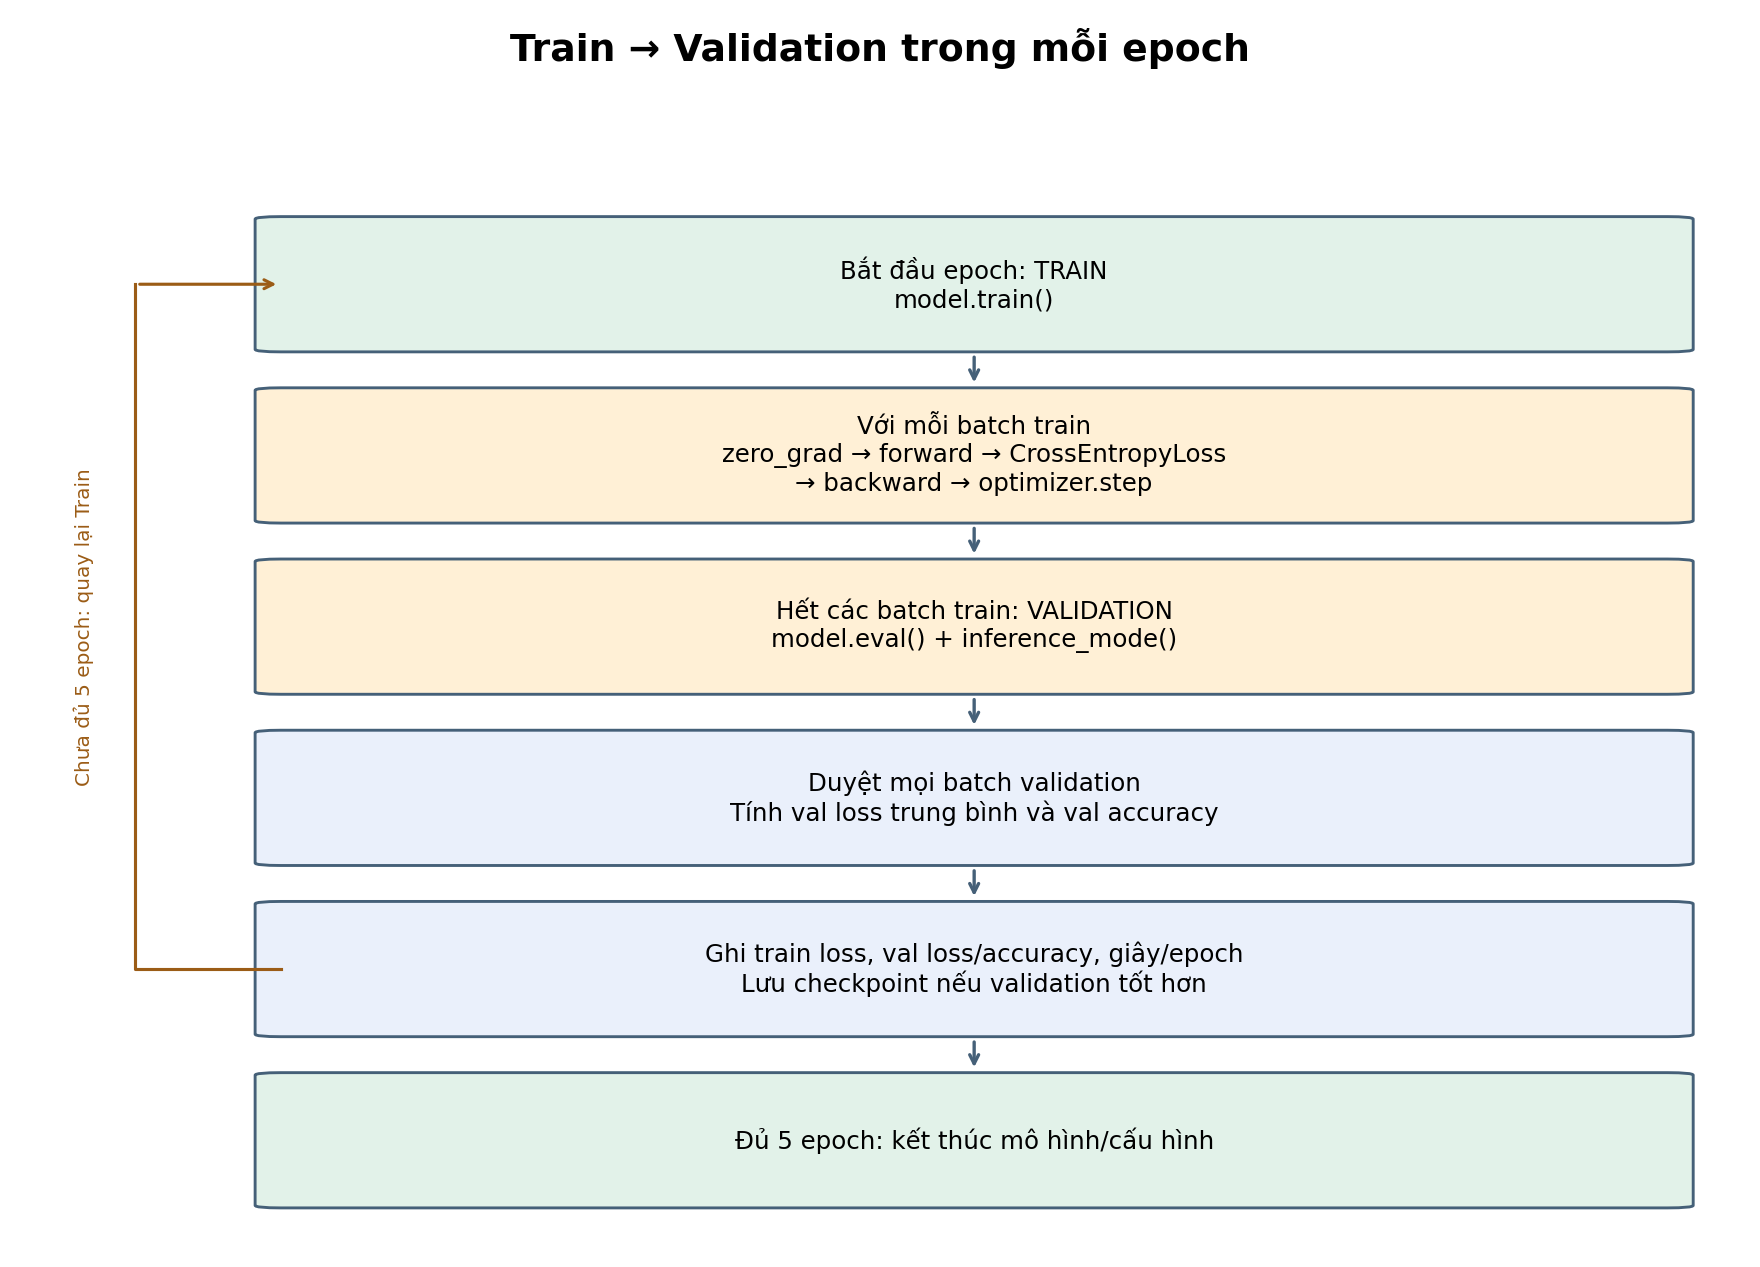

<details>
<summary>Mã Mermaid để chỉnh sửa sơ đồ</summary>

```mermaid
flowchart TD
    N0["Bắt đầu epoch: TRAIN<br/>model.train()"]
    N1["Với mỗi batch train<br/>zero_grad → forward → CrossEntropyLoss<br/>→ backward → optimizer.step"]
    N0 --> N1
    N2["Hết các batch train: VALIDATION<br/>model.eval() + inference_mode()"]
    N1 --> N2
    N3["Duyệt mọi batch validation<br/>Tính val loss trung bình và val accuracy"]
    N2 --> N3
    N4["Ghi train loss, val loss/accuracy, giây/epoch<br/>Lưu checkpoint nếu validation tốt hơn"]
    N3 --> N4
    N5["Đủ 5 epoch: kết thúc mô hình/cấu hình"]
    N4 --> N5
    N4 -->|"Chưa đủ 5 epoch"| N0
```

</details>

**Train cập nhật trọng số. Validation chỉ đo chất lượng và chọn checkpoint.** Bước cập nhật được thực hiện sau mỗi batch train; validation chạy ở cuối epoch. Cả hai bài đều dùng vòng học này. Test riêng của bài 2 diễn ra sau khi đã chọn mô hình.


## 3. Huấn luyện và đánh giá

Vòng học: zero_grad → forward → CrossEntropyLoss → backward → step. Dùng `train()` khi học, `eval()` và `inference_mode()` khi đánh giá. Loss lấy trung bình theo số mẫu, kể cả batch cuối thiếu. Train loss là loss trong khi cập nhật; validation loss đo ở cuối epoch. Thời gian gồm train + validation, không gồm ghi checkpoint hoặc vẽ hình.

In [4]:
display(Code(inspect.getsource(common.train_one_epoch), language="python"))
display(Code(inspect.getsource(common.evaluate), language="python"))
display(Code(inspect.getsource(common.fit), language="python"))

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, count = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        count += y.size(0)
    return total_loss / count

@torch.inference_mode()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        total_loss += criterion(logits, y).item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        count += y.size(0)
    return total_loss / count, correct / count

def fit(name, model, train_ds, val_ds, output):
    model = model.to(DEVICE)
    train_loader, val_loader = make_loaders(train_ds, val_ds)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()
    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n{name} | device={DEVICE} | parameters={parameters}", flush=True)
    history, best_key, best_row = [], None, None
    for epoch in range(1, EPOCHS + 1):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
        row = dict(model=name, epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                   val_accuracy=val_acc, seconds=elapsed)
        history.append(row)
        print(f"Epoch {epoch}/{EPOCHS}: device={DEVICE}, train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, "
              f"val_acc={val_acc:.2%}, time={elapsed:.2f}s", flush=True)
        key = (val_acc, -val_loss)
        if best_key is None or key > best_key:
            best_key, best_row = key, row.copy()
            torch.save({"state_dict": model.state_dict(), "epoch": epoch,
                        "val_accuracy": val_acc, "val_loss": val_loss}, output / f"{name}_best.pt")
    summary = dict(model=name, parameters=parameters, final_train_loss=history[-1]["train_loss"],
                   final_val_loss=history[-1]["val_loss"], final_val_accuracy=history[-1]["val_accuracy"],
                   mean_seconds_per_epoch=float(np.mean([r["seconds"] for r in history])),
                   best_epoch=best_row["epoch"], best_val_loss=best_row["val_loss"],
                   best_val_accuracy=best_row["val_accuracy"])
    return summary, history

## 4. Đánh giá test và ma trận của cả 6 cấu hình

Confusion matrix: hàng thật, cột dự đoán. Mỗi cấu hình dùng checkpoint validation tốt nhất, đánh giá cùng 10.000 ảnh test. Giữ nguyên mô hình chính được chọn bằng validation. 5 ảnh đúng và 5 ảnh sai là của mô hình chính.

In [5]:
display(Code(inspect.getsource(exercise.predict_test), language="python"))
display(Code(inspect.getsource(exercise.final_test), language="python"))
display(Code(inspect.getsource(exercise.evaluate_all_configurations), language="python"))

@torch.inference_mode()
def predict_test(model, loader):
    """Forward ở eval; trả dự đoán và loss, không cập nhật trọng số."""
    model.eval()
    predictions, total_loss, count = [], 0.0, 0
    criterion = nn.CrossEntropyLoss()
    for x, y in loader:
        logits = model(x.to(DEVICE))
        total_loss += criterion(logits, y.to(DEVICE)).item() * len(y)
        predictions.append(logits.argmax(1).cpu())
        count += len(y)
    return torch.cat(predictions), total_loss / count

def final_test(model, output, title="Selected model | official test"):
    """Chỉ gọi sau khi đã khóa lựa chọn mô hình bằng validation."""
    images, labels = read_official(train=False)
    dataset = TensorDataset(images.float().div_(255), labels)
    loader = DataLoader(dataset, batch_size=256, shuffle=False)
    predicted, loss = predict_test(model, loader)
    cm = save_test_outputs(output, labels, predicted, title)
    example_records = []
    for correct, filename in ((True, "correct_examples.png"), (False, "incorrect_examples.png")):
        ids = torch.where((labels == predicted) == correct)[0][:5]
        if len(ids) < 5:
            raise RuntimeError(f"Chỉ có {len(ids)} ảnh {'đúng' if correct else 'sai'} trên test")
        fig, axes = plt.subplots(1, 5, figsize=(14, 3.4))
        for ax, i in zip(axes, ids.tolist()):
            ax.imshow(images[i, 0], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"#{i}\nTrue: {CLASSES[labels[i]]}\nPred: {CLASSES[predicted[i]]}", fontsize=9)
            ax.axis("off")
            example_records.append(dict(test_index=i, true=int(labels[i]), predicted=int(predicted[i]), correct=correct))
        fig.suptitle("Five correct predictions" if correct else "Five incorrect predictions")
        fig.tight_layout(rect=(0, 0, 1, 0.84))
        fig.savefig(output / filename, dpi=160)
        plt.close(fig)
    save_csv(output / "example_indices.csv", example_records)
    return dict(test_size=len(labels), test_loss=loss,
                test_accuracy=float((labels == predicted).float().mean()),
                confusion_accuracy=float(np.trace(cm) / cm.sum()))

def evaluate_all_configurations(output):
    """Đánh giá các checkpoint đã chọn bằng validation; giữ nguyên selection.json."""
    selected = json.loads((output / "selection.json").read_text(encoding="utf-8"))
    configs = json.loads((output / "configurations.json").read_text(encoding="utf-8"))
    checkpoints = {config["name"]: torch.load(output / f"{config['name']}_best.pt",
                   map_location=DEVICE, weights_only=True) for config in configs}
    assert checkpoints[selected["model"]]["epoch"] == selected["epoch"]
    images, labels = read_official(train=False)
    loader = DataLoader(TensorDataset(images.float().div_(255), labels), batch_size=256, shuffle=False)
    target = output / "test_all_configs"
    rows, matrices = [], []
    for config in configs:
        name = config["name"]
        checkpoint = checkpoints[name]
        model = CNN2Blocks(**{k: v for k, v in config.items() if k != "name"}).to(DEVICE)
        model.load_state_dict(checkpoint["state_dict"])
        predicted, loss = predict_test(model, loader)
        folder = target / name
        cm = save_test_outputs(folder, labels, predicted,
                              f"{name} | epoch {checkpoint['epoch']} | official test")
        correct = int(np.trace(cm))
        row = dict(model=name, epoch=checkpoint["epoch"], validation_accuracy=checkpoint["val_accuracy"],
                   validation_loss=checkpoint["val_loss"], test_size=len(labels), test_loss=loss,
                   test_accuracy=correct / len(labels), correct=correct, incorrect=len(labels)-correct,
                   selected_by_validation=name == selected["model"], checkpoint=f"{name}_best.pt")
        save_json(folder / "test_metrics.json", row)
        rows.append(row)
        matrices.append(cm)
        print(f"Test {name}: epoch={row['epoch']} | accuracy={row['test_accuracy']:.2%}", flush=True)
    save_csv(target / "summary.csv", rows)
    fig, axes = plt.subplots(3, 2, figsize=(18, 23), constrained_layout=True)
    for ax, row, cm in zip(axes.flat, rows, matrices):
        marker = " | selected by validation" if row["selected_by_validation"] else ""
        plot_confusion(ax, cm, f"{row['model']} | epoch {row['epoch']} | test {row['test_accuracy']:.2%}{marker}", 8)
    fig.suptitle("Official test: 10,000 images per configuration | rows=true, columns=predicted", fontsize=16)
    fig.savefig(target / "confusion_matrices.png", dpi=150)
    plt.close(fig)
    return rows

## Chạy thí nghiệm

Cell này gọi trực tiếp `main()` của script cùng tên; học đủ 5 epoch mỗi cấu hình. Các file dữ liệu và checkpoint được tạo theo đúng quy trình trong mã nguồn.

In [6]:
exercise.main()

Device: cpu | FashionMNIST | train: 6000 | validation: 1200


Shape probe: zero input, CPU, eval mode; not training/test predictions.

=== baseline | parameters=206,922 ===
input: (1, 1, 28, 28)
conv1: (1, 16, 28, 28) | Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
bn1: (1, 16, 28, 28) | Identity()
relu1: (1, 16, 28, 28) | ReLU()
pool1: (1, 16, 14, 14) | MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
conv2: (1, 32, 14, 14) | Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
bn2: (1, 32, 14, 14) | Identity()
relu2: (1, 32, 14, 14) | ReLU()
pool2: (1, 32, 7, 7) | MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
flatten: (1, 1568) | Flatten(start_dim=1, end_dim=-1)
fc1: (1, 128) | Linear(in_features=1568, out_features=128, bias=True)
relu3: (1, 128) | ReLU()
drop: (1, 128) | Dropout(p=0.0, inplace=False)
fc2: (1, 10) | Linear(in_features=128, out_features=10, bias=True)
input: (64, 1, 28, 28)
conv1: (64, 16, 28, 28) | Conv2d(1, 16, kernel_size=(3, 3), stride=(1,


baseline | device=cpu | parameters=206922


Epoch 1/5: device=cpu, train_loss=1.1296, val_loss=0.6584, val_acc=76.92%, time=0.69s


Epoch 2/5: device=cpu, train_loss=0.6478, val_loss=0.5777, val_acc=78.75%, time=0.69s


...

Epoch 3/5: device=cpu, train_loss=0.6114, val_loss=0.5219, val_acc=79.50%, time=0.73s


Epoch 4/5: device=cpu, train_loss=0.5553, val_loss=0.5016, val_acc=81.17%, time=0.71s


Epoch 5/5: device=cpu, train_loss=0.5220, val_loss=0.4428, val_acc=83.75%, time=0.71s



| Mô hình | Tham số | Val loss | Val accuracy | Giây/epoch | Epoch báo cáo |
|---|---:|---:|---:|---:|---:|
| baseline | 206,922 | 0.4319 | 86.17% | 0.691 | 5 |
| kernel5 | 215,370 | 0.4003 | 85.75% | 0.895 | 5 |
| channels8 | 103,018 | 0.4650 | 83.67% | 0.389 | 5 |
| channels32 | 421,642 | 0.4130 | 86.58% | 1.547 | 3 |
| batchnorm | 207,018 | 0.3297 | 88.58% | 0.877 | 4 |
| dropout03 | 206,922 | 0.4428 | 83.75% | 0.716 | 5 |


Selected: batchnorm epoch 4 | test accuracy=86.44%


## Bảng kết quả từng epoch, learning curve và nhận xét

Bảng chi tiết hiển thị đủ epoch 1–5 cho từng mô hình: train loss, val loss, val accuracy, thay đổi accuracy và thời gian. Epoch in đậm là checkpoint validation tốt nhất; xem ghi chú để phân biệt với epoch cuối và mô hình chính được chọn.

# Thực hành 2 — Lê Sơn Trường

<!-- BEGIN VARIANT_DETAILS -->

### Mục tiêu, đầu vào và đầu ra của bài 2

Dùng CNN của bài 1 làm baseline, rồi khảo sát riêng từng thay đổi: kernel, số kênh, BatchNorm và Dropout. Bài 1 so sánh MLP–CNN tại epoch cuối; bài 2 chọn checkpoint tốt nhất bằng validation rồi mới đánh giá test.

| Thành phần | Thông tin |
|---|---|
| Dữ liệu | FashionMNIST; ảnh xám 28×28, 10 lớp trang phục |
| Train | 6,000 ảnh từ official train; dùng cập nhật trọng số |
| Validation | 1,200 ảnh khác từ official train; chọn epoch/cấu hình |
| Test | 10,000 ảnh official test độc lập; đánh giá cuối và phân tích ma trận từng cấu hình |
| Tiền xử lý | Pixel float32 /255 thuộc [0,1], không augmentation; nhãn long 0–9 |
| Đầu vào | `(N,1,28,28)` |
| Đầu ra | `(N,10)` logits; argmax cho nhãn; CrossEntropyLoss nhận trực tiếp logits |

### Thiết lập và quy trình huấn luyện

| Thành phần | Giá trị |
|---|---|
| Thiết bị / môi trường | cpu; PyTorch 2.14.1+cpu; 2 threads |
| Seed | 42; cùng split và thứ tự batch cho mọi cấu hình |
| Optimizer / learning rate | Adam / 0.001 |
| Epoch | 5 cho mỗi cấu hình; 6 cấu hình, 30 dòng log |
| Batch | Train 64; validation/test 256 |
| Số batch train/epoch | 94; batch cuối 48 ảnh, vẫn được sử dụng |
| Loss | CrossEntropyLoss; lấy trung bình theo số mẫu |

Mỗi epoch: **train() → zero_grad → forward → loss → backward → optimizer.step** trên các batch train; sau đó **eval() + inference_mode()** trên validation. Chạy đủ số epoch, không Early Stopping. Thời gian/epoch gồm train + validation, không gồm kiểm tra shape, ghi checkpoint hay vẽ biểu đồ. Train loss đo trong lúc cập nhật; validation loss đo ở cuối epoch.

### Kiến trúc và shape của đủ 6 cấu hình

Shape có thứ tự `(N,C,H,W)`; N là số ảnh trong batch. Các shape dưới đây được ghi bằng hook trên `forward()` thật, với input giả bằng 0, chế độ eval trên CPU; đây là kiểm tra kiến trúc.

| Cấu hình | Sau Conv1 | Sau Pool1 | Sau Conv2 | Sau Pool2 | Sau Flatten | Đầu ra |
|---|---|---|---|---|---|---|
| baseline | `(N,16,28,28)` | `(N,16,14,14)` | `(N,32,14,14)` | `(N,32,7,7)` | `(N,1568)` | `(N,10)` |
| kernel5 | `(N,16,28,28)` | `(N,16,14,14)` | `(N,32,14,14)` | `(N,32,7,7)` | `(N,1568)` | `(N,10)` |
| channels8 | `(N,8,28,28)` | `(N,8,14,14)` | `(N,16,14,14)` | `(N,16,7,7)` | `(N,784)` | `(N,10)` |
| channels32 | `(N,32,28,28)` | `(N,32,14,14)` | `(N,64,14,14)` | `(N,64,7,7)` | `(N,3136)` | `(N,10)` |
| batchnorm | `(N,16,28,28)` | `(N,16,14,14)` | `(N,32,14,14)` | `(N,32,7,7)` | `(N,1568)` | `(N,10)` |
| dropout03 | `(N,16,28,28)` | `(N,16,14,14)` | `(N,32,14,14)` | `(N,32,7,7)` | `(N,1568)` | `(N,10)` |

ReLU giữ shape. Kernel3 dùng padding1, kernel5 dùng padding2 nên convolution giữ H,W; MaxPool2d(2) mới giảm 28→14→7. BatchNorm giữ shape và nằm giữa Conv–ReLU trong mỗi block. Dropout0.3 nằm sau ReLU của Linear128; các cấu hình khác có Dropout p=0. Phần phân loại: Flatten → Linear128 → ReLU → Dropout → Linear10. `argmax` trên 10 logits cho nhãn dự đoán.

### Phân bố số tham số

| Cấu hình | Block 1 (Conv + BN) | Block 2 (Conv + BN) | Phân loại (2 Linear) | Tổng |
|---|---:|---:|---:|---:|
| baseline | 160 | 4,640 | 202,122 | 206,922 |
| kernel5 | 416 | 12,832 | 202,122 | 215,370 |
| channels8 | 80 | 1,168 | 101,770 | 103,018 |
| channels32 | 320 | 18,496 | 402,826 | 421,642 |
| batchnorm | 192 | 4,704 | 202,122 | 207,018 |
| dropout03 | 160 | 4,640 | 202,122 | 206,922 |

Conv có `C_out × (C_in × k × k + 1)` tham số; Linear có `n_out × (n_in + 1)`, đã tính bias. BatchNorm có 2 tham số học được cho mỗi kênh (scale và bias); running statistics không tính vào tham số học được. ReLU, MaxPool, Flatten, Dropout và Identity không có tham số học được.

Ở baseline, phần phân loại chiếm **97.68%** tham số. Tăng số kênh còn làm tăng đầu vào của Linear đầu tiên. Dropout không thêm tham số; BatchNorm thêm một lượng nhỏ tham số.

[Nhật ký shape từng lớp, batch 1 và 64](shapes.txt) · [Kiến trúc và tham số dạng JSON](architectures.json)

### Mức thay đổi so với baseline

So sánh accuracy tại checkpoint validation tốt nhất của từng cấu hình; Δ accuracy tính bằng điểm phần trăm. Tỷ lệ thời gian >1 nghĩa là chậm hơn baseline trong lần chạy này; thời gian phụ thuộc máy và tải hệ thống.

| Cấu hình | Thay đổi duy nhất | Δ tham số | Δ val accuracy (điểm %) | Thời gian / baseline |
|---|---|---:|---:|---:|
| baseline | Mốc: k3, kênh16/32 | +0 | +0.00 | 1.00× |
| kernel5 | Kernel3→5, padding1→2 | +8,448 | -0.42 | 1.30× |
| channels8 | Kênh16/32→8/16 | -103,904 | -2.50 | 0.56× |
| channels32 | Kênh16/32→32/64 | +214,720 | +0.42 | 2.24× |
| batchnorm | Thêm BatchNorm sau mỗi Conv | +96 | +2.42 | 1.27× |
| dropout03 | Dropout p=0→0.3 sau Linear128 + ReLU | +0 | -2.42 | 1.04× |

### Chọn checkpoint, đánh giá test và đọc lỗi

1. Trong mỗi cấu hình, giữ epoch có validation accuracy lớn nhất; hòa thì chọn validation loss nhỏ hơn; hòa cả hai giữ epoch gặp trước.
2. So sánh checkpoint tốt nhất của 6 cấu hình theo cùng quy tắc; lưu lựa chọn vào `selection.json` trước khi đọc test.
3. Nạp [batchnorm_best.pt](batchnorm_best.pt) ở epoch **4**, có validation accuracy **88.58%**, validation loss **0.3297**.
4. Đánh giá đủ **10,000** ảnh test: accuracy **86.44%**, loss **0.3762**. Phần ma trận bổ sung đánh giá cả 6 checkpoint trên test để phân tích lỗi, giữ nguyên lựa chọn đã khóa bằng validation.

Confusion matrix: **hàng là nhãn thật, cột là dự đoán**. Tổng đường chéo **8,644/10,000** là số ảnh đúng; còn **1,356** ảnh sai. Lớp có tỷ lệ nhận đúng thấp nhất là **Shirt**: 623/1000 ảnh (62.30%).

- Nhầm Coat → Pullover: 127 ảnh.
- Nhầm Shirt → T-shirt/top: 119 ảnh.
- Nhầm Shirt → Pullover: 117 ảnh.

Ảnh minh họa gồm 5 ảnh đúng và 5 ảnh sai đầu tiên theo thứ tự test, có nhãn thật/dự đoán; đây là ví dụ để quan sát lỗi. Độ chính xác và confusion matrix được tính trên toàn bộ test.

### Gợi ý trình bày với giảng viên

Trình bày theo thứ tự: **mục tiêu → dữ liệu/đầu ra → hai block và shape → thiết lập/vòng học → so sánh 6 cấu hình → chọn mô hình/test → lỗi và kết luận**.

> Em dùng FashionMNIST, chia 6,000 ảnh train và 1,200 ảnh validation từ tập train chính thức. Đầu vào là ảnh xám 1×28×28; đầu ra gồm 10 logits. CNN baseline có hai block Conv–ReLU–MaxPool với 16/32 kênh; sau hai lần pooling, tensor thành 32×7×7, Flatten thành 1568 rồi đưa qua Linear128 và Linear10.

> Em giữ Adam, learning rate 0.001, batch 64, seed 42 và 5 epoch cho mỗi cấu hình. Em thay riêng kernel, số kênh, thêm BatchNorm hoặc Dropout để so sánh với baseline. Mô hình được chọn là batchnorm tại epoch 4, validation accuracy 88.58%. Sau khi khóa lựa chọn, em đánh giá 10,000 ảnh test độc lập, đạt accuracy 86.44%.

> Confusion matrix cho thấy lớp Shirt còn khó phân biệt. Kết quả mới có một seed và 5 epoch nên em chưa kết luận cấu hình thắng luôn tốt nhất, hoặc khẳng định overfitting chỉ từ một epoch giảm accuracy. Hướng cải thiện có thể thử là thêm dữ liệu/augmentation, khảo sát learning rate và thời gian học dựa trên validation.

<!-- END VARIANT_DETAILS -->

| Cấu hình | Channels | Kernel | BatchNorm | Dropout |
|---|---|---|---|---|
| baseline | 16/32 | 3 | False | 0.0 |
| kernel5 | 16/32 | 5 | False | 0.0 |
| channels8 | 8/16 | 3 | False | 0.0 |
| channels32 | 32/64 | 3 | False | 0.0 |
| batchnorm | 16/32 | 3 | True | 0.0 |
| dropout03 | 16/32 | 3 | False | 0.3 |

Baseline đại diện kernel3 và channel16 ở block1. Các biến thể bao phủ kernel **3/5** và channel block1 **8/16/32**; block2 có số kênh gấp đôi block1. Mỗi biến thể chỉ đổi một thuộc tính so với baseline để phân tích riêng ảnh hưởng của nó.

| Mô hình | Tham số | Val loss | Val accuracy | Giây/epoch | Epoch báo cáo |
|---|---:|---:|---:|---:|---:|
| baseline | 206,922 | 0.4319 | 86.17% | 0.691 | 5 |
| kernel5 | 215,370 | 0.4003 | 85.75% | 0.895 | 5 |
| channels8 | 103,018 | 0.4650 | 83.67% | 0.389 | 5 |
| channels32 | 421,642 | 0.4130 | 86.58% | 1.547 | 3 |
| batchnorm | 207,018 | 0.3297 | 88.58% | 0.877 | 4 |
| dropout03 | 206,922 | 0.4428 | 83.75% | 0.716 | 5 |

Bảng báo cáo checkpoint validation tốt nhất của mỗi cấu hình; history.csv lưu mọi epoch.

<!-- BEGIN EPOCH_DETAILS -->

### Kết quả đầy đủ từng epoch

**Train loss**: trung bình theo số mẫu trong lúc cập nhật. **Val loss/accuracy**: đánh giá ở cuối epoch. **Δ accuracy**: thay đổi so với epoch trước, tính bằng điểm phần trăm. **Giây**: thời gian train + validation của epoch đó.

Epoch **in đậm** có validation accuracy cao nhất của cấu hình; nếu hòa, chọn validation loss nhỏ hơn. Dấu **Mô hình được chọn** chỉ checkpoint thắng giữa các cấu hình theo validation. Phần bổ sung có ma trận test của từng cấu hình; không dùng test để chọn epoch/mô hình.

[Dữ liệu từng epoch: history.csv](history.csv)

#### baseline

| Epoch | Train loss | Val loss | Val accuracy | Δ accuracy (điểm %) | Giây | Ghi chú |
|---:|---:|---:|---:|---:|---:|---|
| 1 | 1.1296 | 0.6584 | 76.92% | — | 0.691 | — |
| 2 | 0.6478 | 0.5777 | 78.75% | +1.83 | 0.685 | — |
| 3 | 0.5521 | 0.4893 | 81.75% | +3.00 | 0.692 | — |
| 4 | 0.4973 | 0.4830 | 82.50% | +0.75 | 0.695 | — |
| **5** | 0.4617 | 0.4319 | 86.17% | +3.67 | 0.689 | Val tốt nhất; Epoch cuối |

Từ epoch 1 → 5: train loss 1.1296 → 0.4617; val loss 0.6584 → 0.4319; val accuracy 76.92% → 86.17%. Accuracy cao nhất là **86.17% tại epoch 5**.

#### kernel5

| Epoch | Train loss | Val loss | Val accuracy | Δ accuracy (điểm %) | Giây | Ghi chú |
|---:|---:|---:|---:|---:|---:|---|
| 1 | 1.0543 | 0.5938 | 78.92% | — | 0.875 | — |
| 2 | 0.5893 | 0.5049 | 81.83% | +2.92 | 0.881 | — |
| 3 | 0.4897 | 0.4623 | 84.33% | +2.50 | 0.910 | — |
| 4 | 0.4421 | 0.4371 | 83.83% | -0.50 | 0.891 | — |
| **5** | 0.3991 | 0.4003 | 85.75% | +1.92 | 0.917 | Val tốt nhất; Epoch cuối |

Từ epoch 1 → 5: train loss 1.0543 → 0.3991; val loss 0.5938 → 0.4003; val accuracy 78.92% → 85.75%. Accuracy cao nhất là **85.75% tại epoch 5**.

#### channels8

| Epoch | Train loss | Val loss | Val accuracy | Δ accuracy (điểm %) | Giây | Ghi chú |
|---:|---:|---:|---:|---:|---:|---|
| 1 | 1.2316 | 0.7160 | 73.08% | — | 0.387 | — |
| 2 | 0.7038 | 0.6112 | 78.42% | +5.33 | 0.383 | — |
| 3 | 0.6093 | 0.5304 | 80.00% | +1.58 | 0.390 | — |
| 4 | 0.5516 | 0.5207 | 81.92% | +1.92 | 0.397 | — |
| **5** | 0.5141 | 0.4650 | 83.67% | +1.75 | 0.389 | Val tốt nhất; Epoch cuối |

Từ epoch 1 → 5: train loss 1.2316 → 0.5141; val loss 0.7160 → 0.4650; val accuracy 73.08% → 83.67%. Accuracy cao nhất là **83.67% tại epoch 5**.

#### channels32

| Epoch | Train loss | Val loss | Val accuracy | Δ accuracy (điểm %) | Giây | Ghi chú |
|---:|---:|---:|---:|---:|---:|---|
| 1 | 1.0012 | 0.5632 | 79.92% | — | 1.542 | — |
| 2 | 0.5681 | 0.5110 | 81.25% | +1.33 | 1.552 | — |
| **3** | 0.4725 | 0.4130 | 86.58% | +5.33 | 1.536 | Val tốt nhất |
| 4 | 0.4133 | 0.3930 | 86.17% | -0.42 | 1.543 | — |
| 5 | 0.3767 | 0.3780 | 86.50% | +0.33 | 1.560 | Epoch cuối |

Từ epoch 1 → 5: train loss 1.0012 → 0.3767; val loss 0.5632 → 0.3780; val accuracy 79.92% → 86.50%. Accuracy cao nhất là **86.58% tại epoch 3**.

Val loss thấp nhất lại ở **epoch 5** (0.3780). Loss và accuracy đo hai khía cạnh khác nhau, nên epoch có loss thấp nhất không nhất thiết có accuracy cao nhất.

#### batchnorm

| Epoch | Train loss | Val loss | Val accuracy | Δ accuracy (điểm %) | Giây | Ghi chú |
|---:|---:|---:|---:|---:|---:|---|
| 1 | 0.6996 | 0.4256 | 85.17% | — | 0.870 | — |
| 2 | 0.4287 | 0.5018 | 82.08% | -3.08 | 0.858 | — |
| 3 | 0.3578 | 0.3457 | 88.17% | +6.08 | 0.867 | — |
| **4** | 0.2966 | 0.3297 | 88.58% | +0.42 | 0.866 | Val tốt nhất; **Mô hình được chọn** |
| 5 | 0.2737 | 0.3192 | 87.67% | -0.92 | 0.925 | Epoch cuối |

Từ epoch 1 → 5: train loss 0.6996 → 0.2737; val loss 0.4256 → 0.3192; val accuracy 85.17% → 87.67%. Accuracy cao nhất là **88.58% tại epoch 4**.

Val loss thấp nhất lại ở **epoch 5** (0.3192). Loss và accuracy đo hai khía cạnh khác nhau, nên epoch có loss thấp nhất không nhất thiết có accuracy cao nhất.

#### dropout03

| Epoch | Train loss | Val loss | Val accuracy | Δ accuracy (điểm %) | Giây | Ghi chú |
|---:|---:|---:|---:|---:|---:|---|
| 1 | 1.2215 | 0.6842 | 73.92% | — | 0.734 | — |
| 2 | 0.7081 | 0.5576 | 79.42% | +5.50 | 0.705 | — |
| 3 | 0.6114 | 0.5219 | 79.50% | +0.08 | 0.728 | — |
| 4 | 0.5553 | 0.5016 | 81.17% | +1.67 | 0.708 | — |
| **5** | 0.5220 | 0.4428 | 83.75% | +2.58 | 0.707 | Val tốt nhất; Epoch cuối |

Từ epoch 1 → 5: train loss 1.2215 → 0.5220; val loss 0.6842 → 0.4428; val accuracy 73.92% → 83.75%. Accuracy cao nhất là **83.75% tại epoch 5**.

<!-- END EPOCH_DETAILS -->



Dùng 6.000 ảnh train và 1.200 ảnh validation không giao nhau từ official train; 10.000 ảnh official test chỉ được đọc sau khi đã lưu lựa chọn mô hình.

Mỗi cấu hình giữ seed42, split, Adam, lr0.001, batch64 và 5 epoch; mỗi biến thể chỉ thay một thuộc tính so với baseline.

Baseline đạt validation accuracy tốt nhất 86.17% ở epoch 5, với 206,922 tham số.

Kernel 5×5 mở rộng vùng quan sát mỗi convolution và tăng số phép tính; đạt 85.75% validation accuracy (giảm 0.42 điểm phần trăm so với baseline), 215,370 tham số và 0.895 s/epoch.

Giảm số kênh từ 16/32 xuống 8/16 làm giảm tham số và khả năng biểu diễn; đạt 83.67% validation accuracy (giảm 2.50 điểm phần trăm so với baseline), 103,018 tham số và 0.389 s/epoch.

Tăng số kênh từ 16/32 lên 32/64 làm tăng số tham số và khả năng biểu diễn; đạt 86.58% validation accuracy (tăng 0.42 điểm phần trăm so với baseline), 421,642 tham số và 1.547 s/epoch.

BatchNorm dùng thống kê batch khi train và running statistics khi eval; đạt 88.58% validation accuracy (tăng 2.42 điểm phần trăm so với baseline), 207,018 tham số và 0.877 s/epoch.

Dropout tắt ngẫu nhiên 30% activation sau fc1 khi train và tắt cơ chế này khi eval; đạt 83.75% validation accuracy (giảm 2.42 điểm phần trăm so với baseline), 206,922 tham số và 0.716 s/epoch.

Chọn batchnorm tại epoch 4 theo validation; test accuracy cuối cùng là 86.44%, test loss 0.3762.

Confusion matrix có hàng là nhãn thật, cột là nhãn dự đoán; ảnh minh họa là 5 mẫu đúng và 5 mẫu sai đầu tiên theo thứ tự test, không chọn theo mức độ đẹp của kết quả.

Đây là kết quả một seed với 5 epoch, chưa chứng minh biến thể nào luôn tốt hơn; train loss là trung bình khi cập nhật, validation loss dùng eval ở cuối epoch.







<!-- BEGIN TEST_COMPARISON -->

### Ma trận nhầm lẫn trên test của cả 6 cấu hình

Mỗi ma trận dùng **checkpoint validation tốt nhất của cấu hình đó**, đánh giá trên cùng **10.000 ảnh official test**. Hàng là nhãn thật, cột là dự đoán. Đây là phần bổ sung để đối chiếu lỗi của các cấu hình; mô hình chính vẫn được chọn bằng validation trong `selection.json`.

| Cấu hình | Epoch | Val accuracy | Test accuracy | Đúng / Sai | Ma trận riêng |
|---|---:|---:|---:|---:|---|
| baseline | 5 | 86.17% | 83.11% | 8,311 / 1,689 | [Ảnh](test_all_configs/baseline/confusion_matrix.png) · [CSV](test_all_configs/baseline/confusion_matrix.csv) |
| kernel5 | 5 | 85.75% | 84.59% | 8,459 / 1,541 | [Ảnh](test_all_configs/kernel5/confusion_matrix.png) · [CSV](test_all_configs/kernel5/confusion_matrix.csv) |
| channels8 | 5 | 83.67% | 81.31% | 8,131 / 1,869 | [Ảnh](test_all_configs/channels8/confusion_matrix.png) · [CSV](test_all_configs/channels8/confusion_matrix.csv) |
| channels32 | 3 | 86.58% | 84.04% | 8,404 / 1,596 | [Ảnh](test_all_configs/channels32/confusion_matrix.png) · [CSV](test_all_configs/channels32/confusion_matrix.csv) |
| **batchnorm (được chọn)** | 4 | 88.58% | 86.44% | 8,644 / 1,356 | [Ảnh](test_all_configs/batchnorm/confusion_matrix.png) · [CSV](test_all_configs/batchnorm/confusion_matrix.csv) |
| dropout03 | 5 | 83.75% | 82.23% | 8,223 / 1,777 | [Ảnh](test_all_configs/dropout03/confusion_matrix.png) · [CSV](test_all_configs/dropout03/confusion_matrix.csv) |

Các ô trong hình tổng hợp dùng cùng thang màu 0–1.000; mỗi hàng có 1.000 ảnh thật của lớp tương ứng. Tổng đường chéo chia cho 10.000 bằng test accuracy của cấu hình.



[Bảng test đầy đủ, có test loss](test_all_configs/summary.csv)

<!-- END TEST_COMPARISON -->


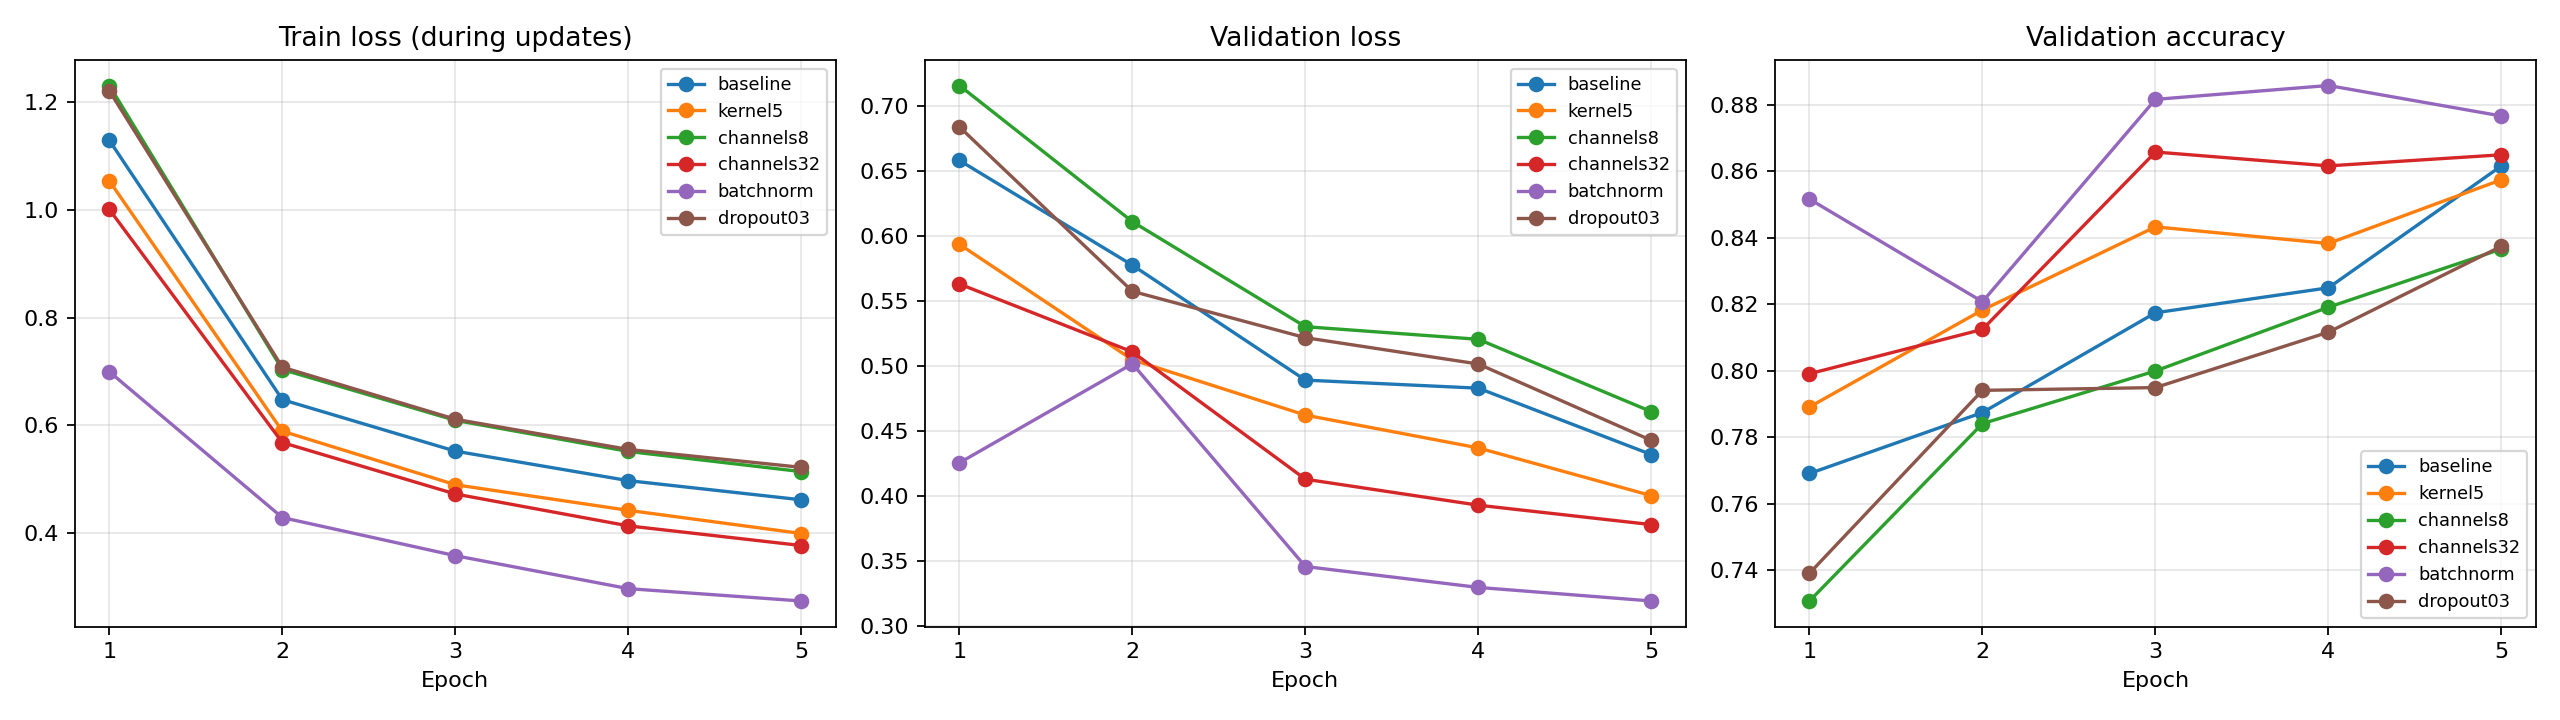

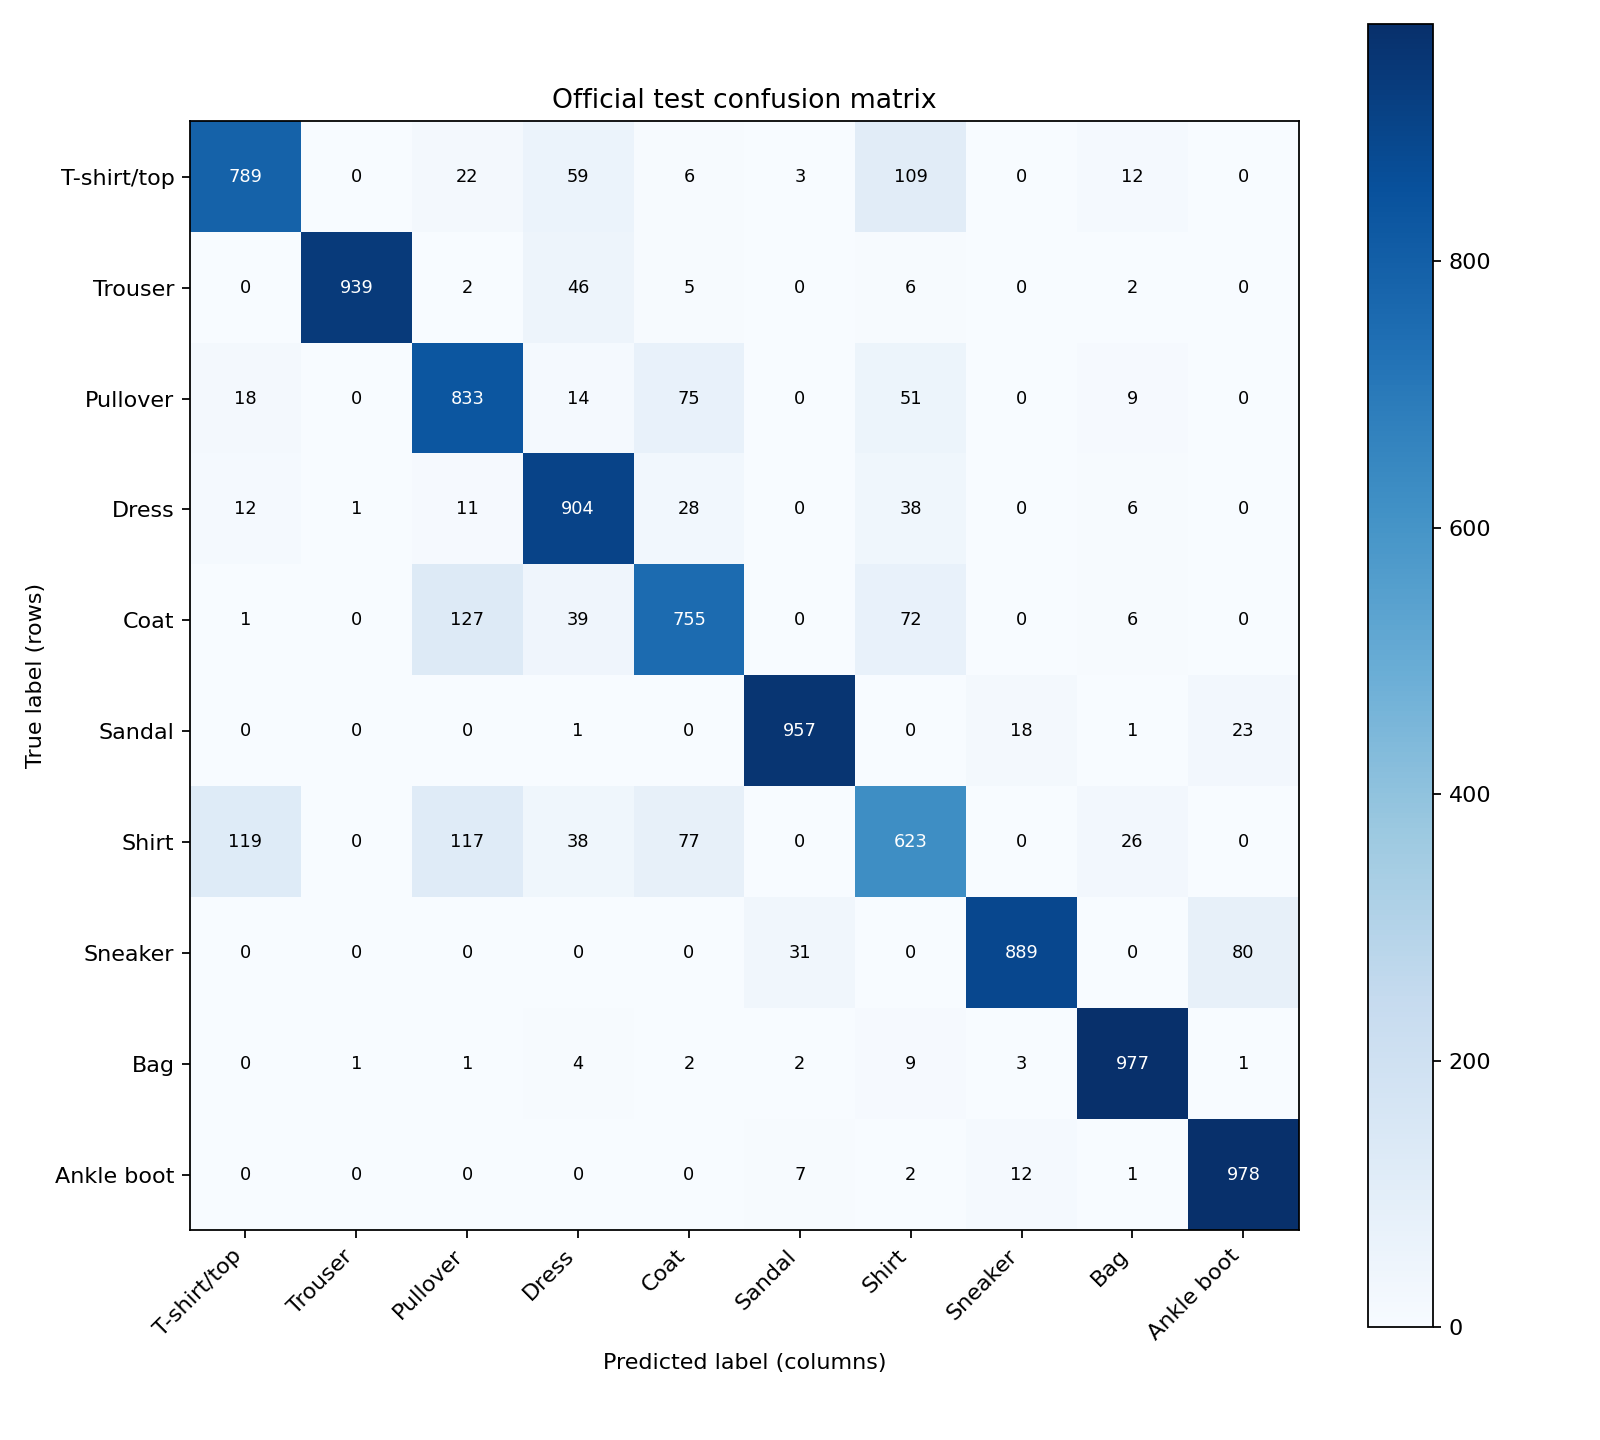

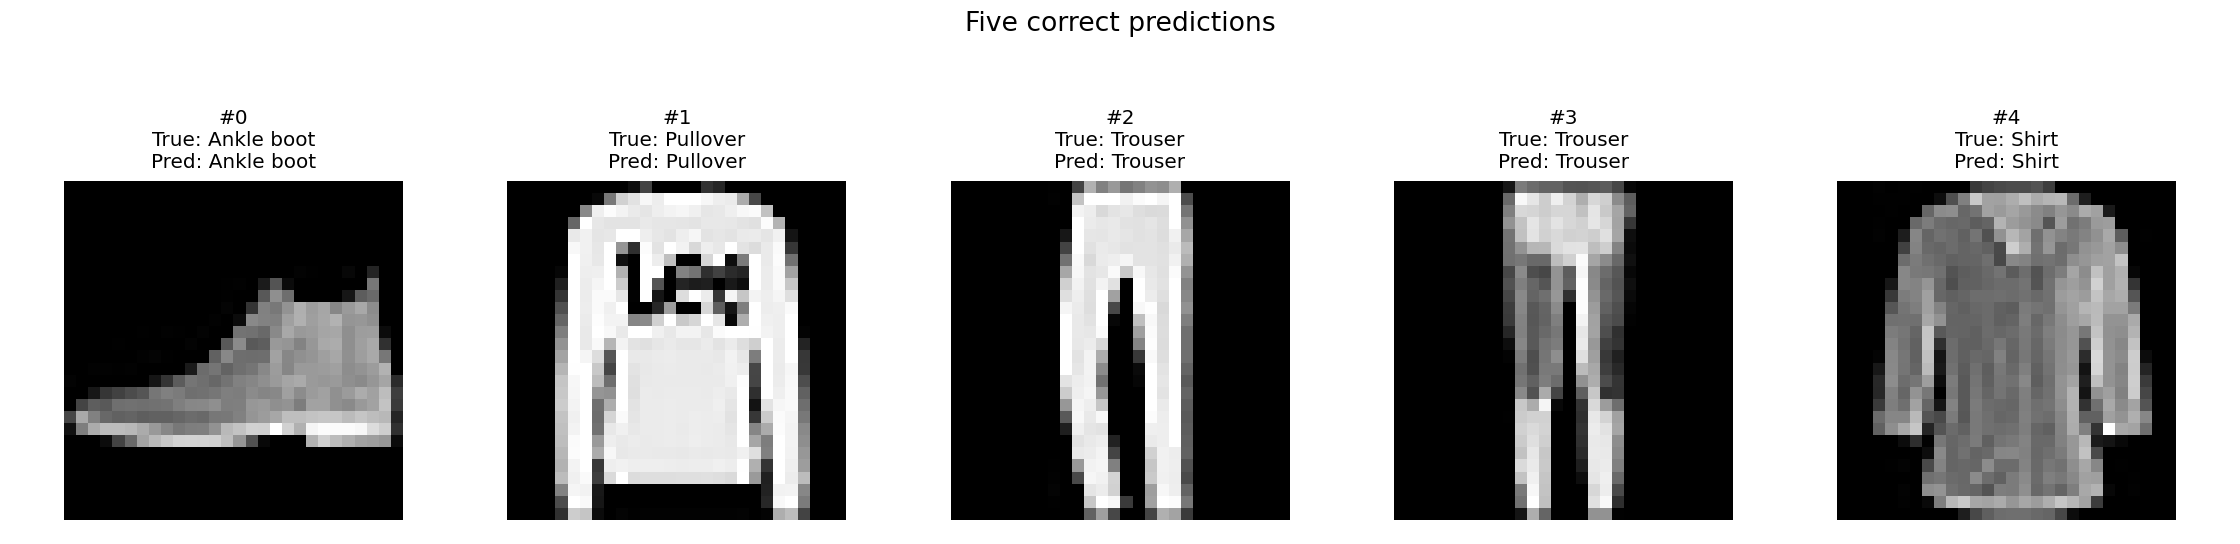

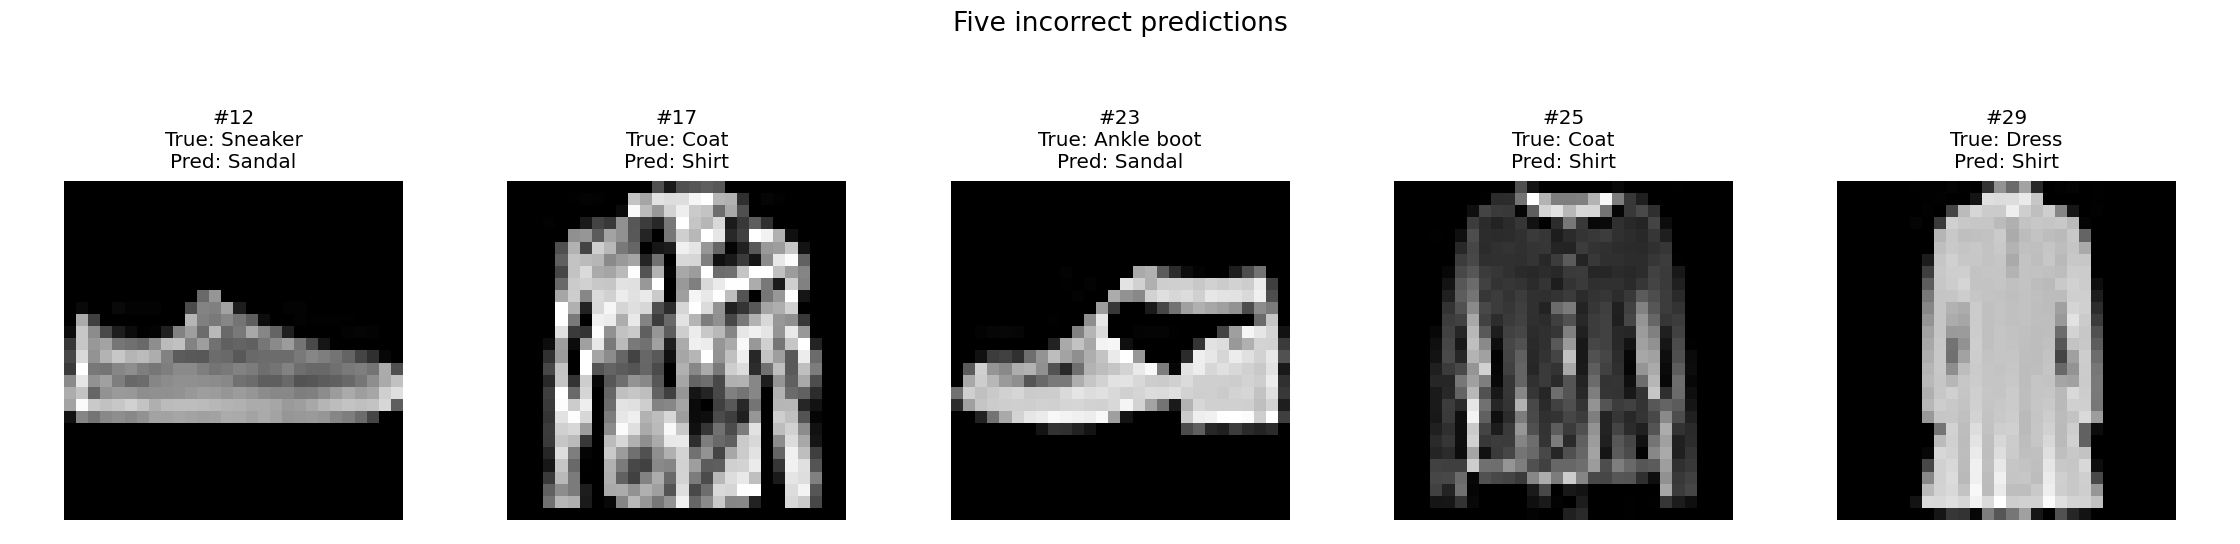

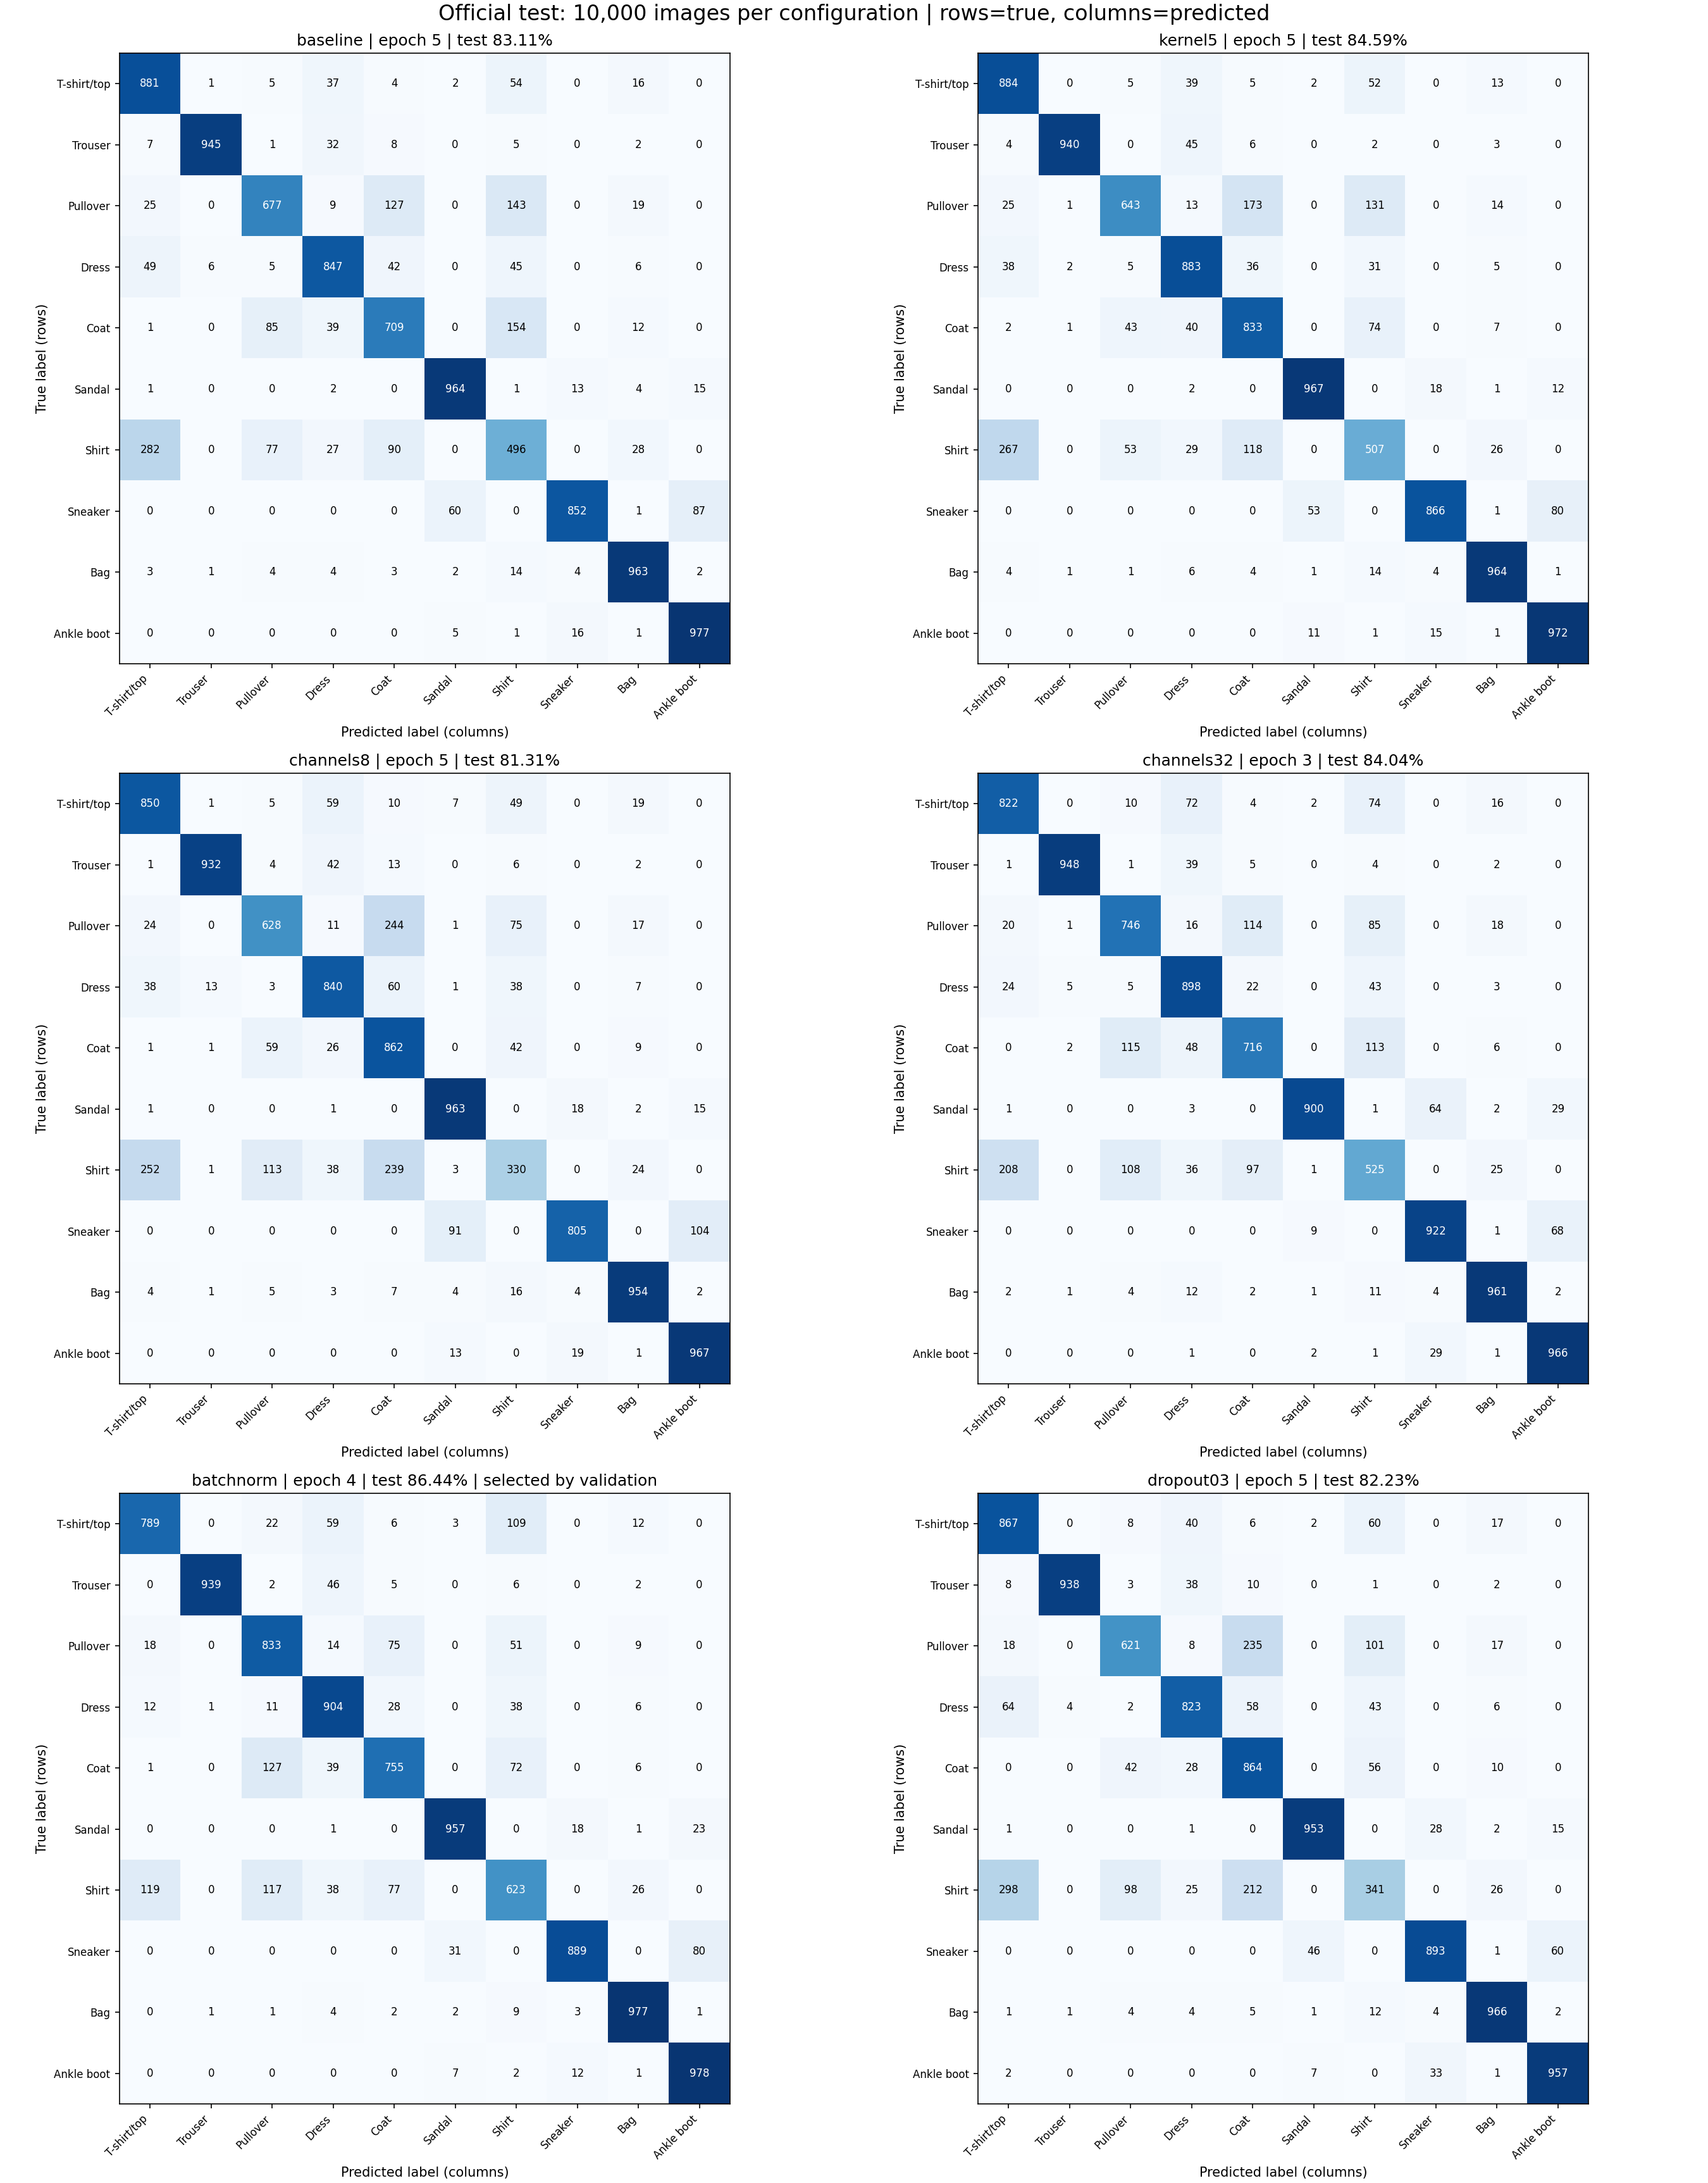

In [6]:
folder = BASE / "results" / "thuc_hanh_2"
report = (folder / "report.md").read_text(encoding="utf-8")
display(Markdown(re.sub(r"!\[[^\]]*\]\([^)]+\)", "", report)))
for filename in ['learning_curves.png', 'confusion_matrix.png', 'correct_examples.png', 'incorrect_examples.png', 'test_all_configs/confusion_matrices.png']:
    display(Image(filename=str(folder / filename)))

## Báo cáo tổng hợp

`BAO_CAO_BUOI4.md` tổng hợp hai bài, kèm hình và phân tích ma trận nhầm lẫn. Khi thay đổi cấu hình, chạy lại cả hai notebook rồi kiểm tra kết quả.

In [7]:
from build_notebooks import write_combined_report
if all((BASE / "results" / task / "report.md").is_file() for task in ["thuc_hanh_1", "thuc_hanh_2"]):
    print("Đã cập nhật:", write_combined_report())
else:
    print("Chạy đủ hai bài để tạo báo cáo tổng hợp.")

Đã cập nhật: C:\Users\LeSonTruong\Documents\GitHub\DeepL\Buoi4\BAO_CAO_BUOI4.md
